## MTL Trajet: 20 Multi User Repeated Trip Variability (Flag 20)

### Dataset Overview
Repeated trips for multiple Montréal users with repeat context, day type, purpose, mode, route deviation, route directness, timing, GPS positions, and point speeds.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze variability in repeated urban trips across multiple users.

Role: Urban mobility-pattern analyst


Category: Repeated trips for multiple Montréal users with repeat context, day type, purpose, mode, route deviation, route directness, timing, GPS positions, and point speeds.

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do weekday-morning work repeats differ from work repeats at other times?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

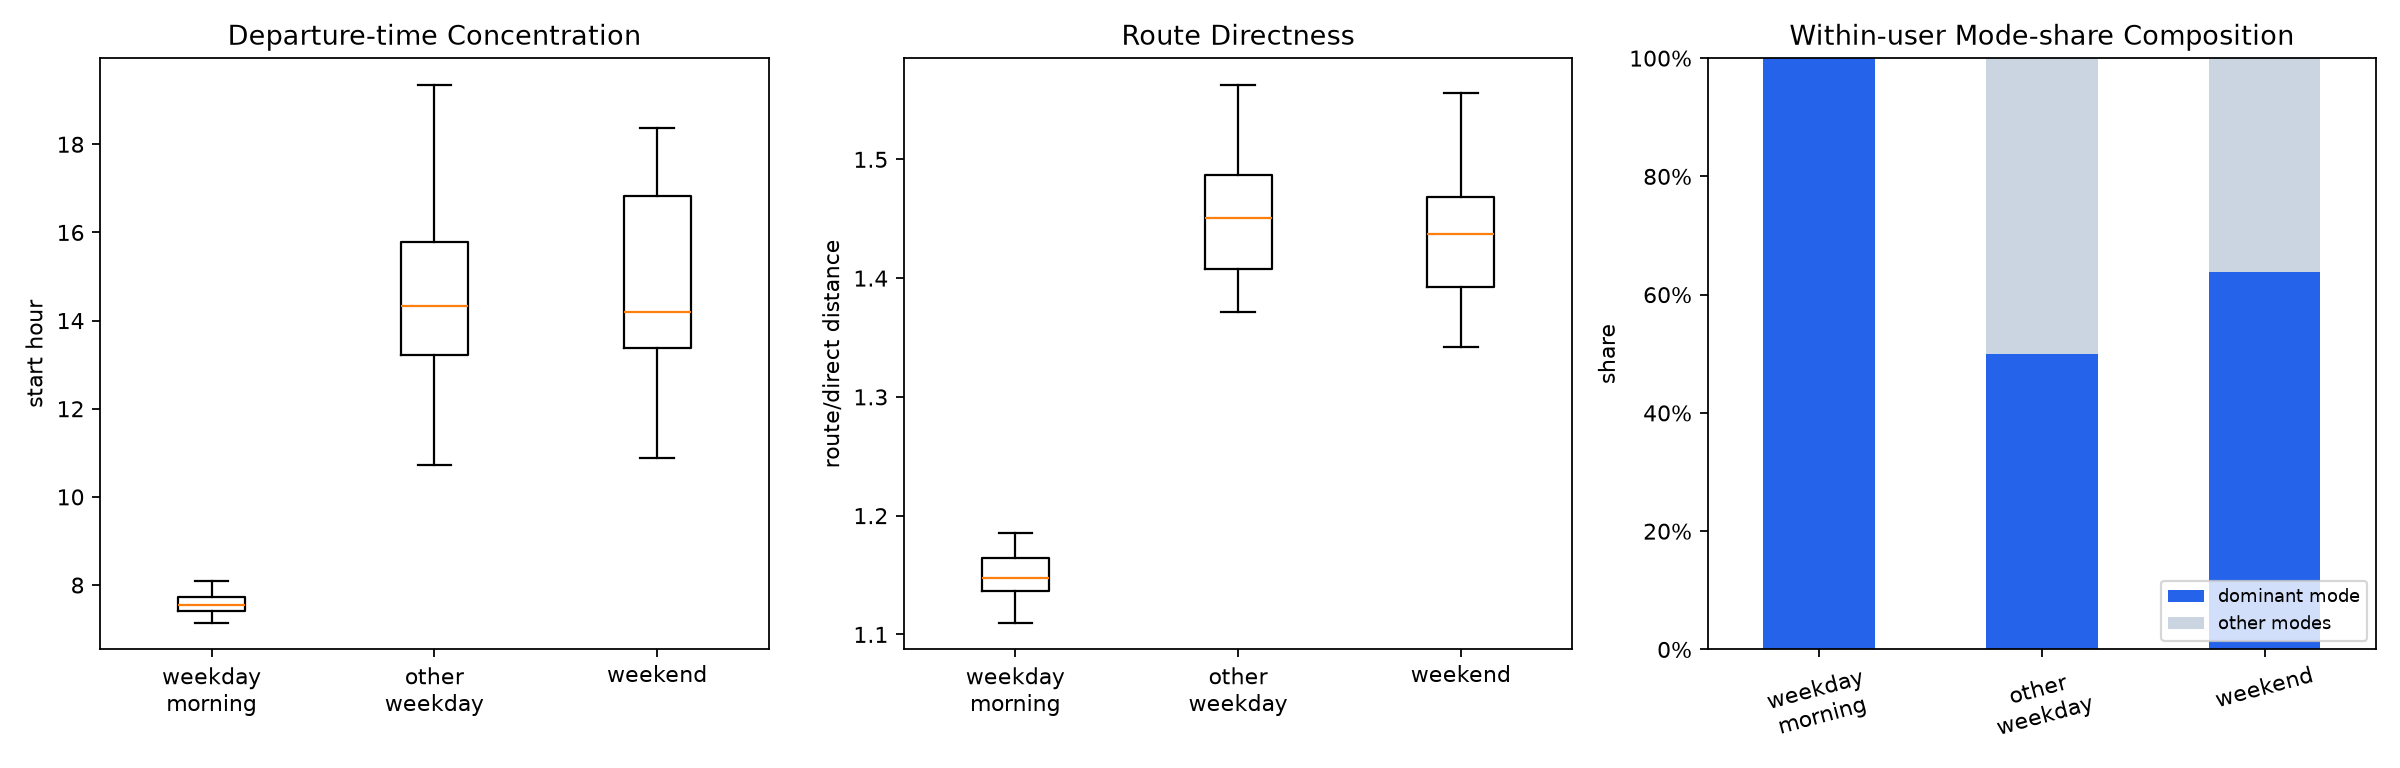

In [ ]:
df.groupby('repeat_context').agg(start_std=('start_hour','std'),mode_consistency=('context_mode_consistency','mean'),directness=('route_directness','median'))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/repeat_context_consistency.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "repeat_context_consistency",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Repeated-trip Timing, Mode, and Directness",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/repeat_context_consistency.png"
  },
  "question": "How do weekday-morning work repeats differ from work repeats at other times?",
  "code": "df.groupby('repeat_context').agg(start_std=('start_hour','std'),mode_consistency=('context_mode_consistency','mean'),directness=('route_directness','median'))",
  "insight": "Work trips between similar locations are more mode-consistent, temporally concentrated, and route-direct on weekday mornings than at other times.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trip_purpose",
    "transport_mode",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position"
  ]
}

### **Question 2**: Among similarly long repeated trips, which users follow stable routes and which show greater route and speed variation?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

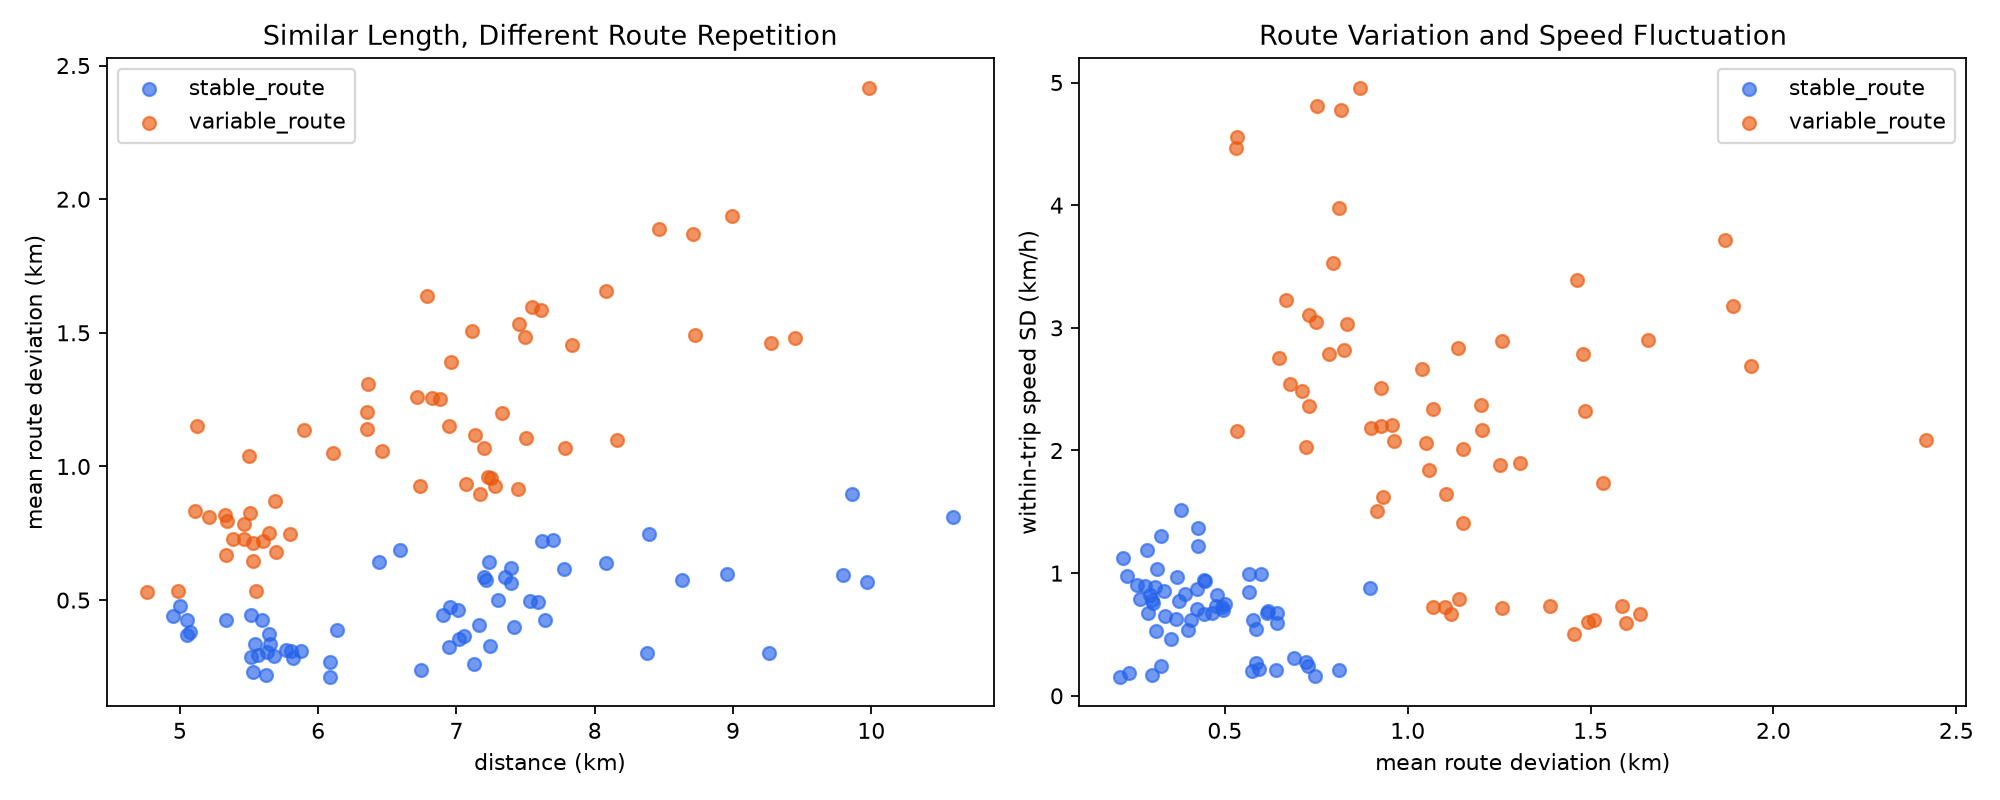

In [ ]:
df.groupby('repeat_style')[['distance_km','mean_route_deviation_km','point_speed_std_kmh']].agg(['median','mean'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/user_route_speed_variability.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "user_route_speed_variability",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "User Route and Speed Variability",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/user_route_speed_variability.png"
  },
  "question": "Among similarly long repeated trips, which users follow stable routes and which show greater route and speed variation?",
  "code": "df.groupby('repeat_style')[['distance_km','mean_route_deviation_km','point_speed_std_kmh']].agg(['median','mean'])",
  "insight": "For similarly long trips, some users repeatedly travel between the same locations along similar routes, while others take varied routes with larger speed fluctuations.",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "point_speed",
    "trajectory_id"
  ]
}

### **Question 3**: How do weekend repeats differ from weekday work repeats?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

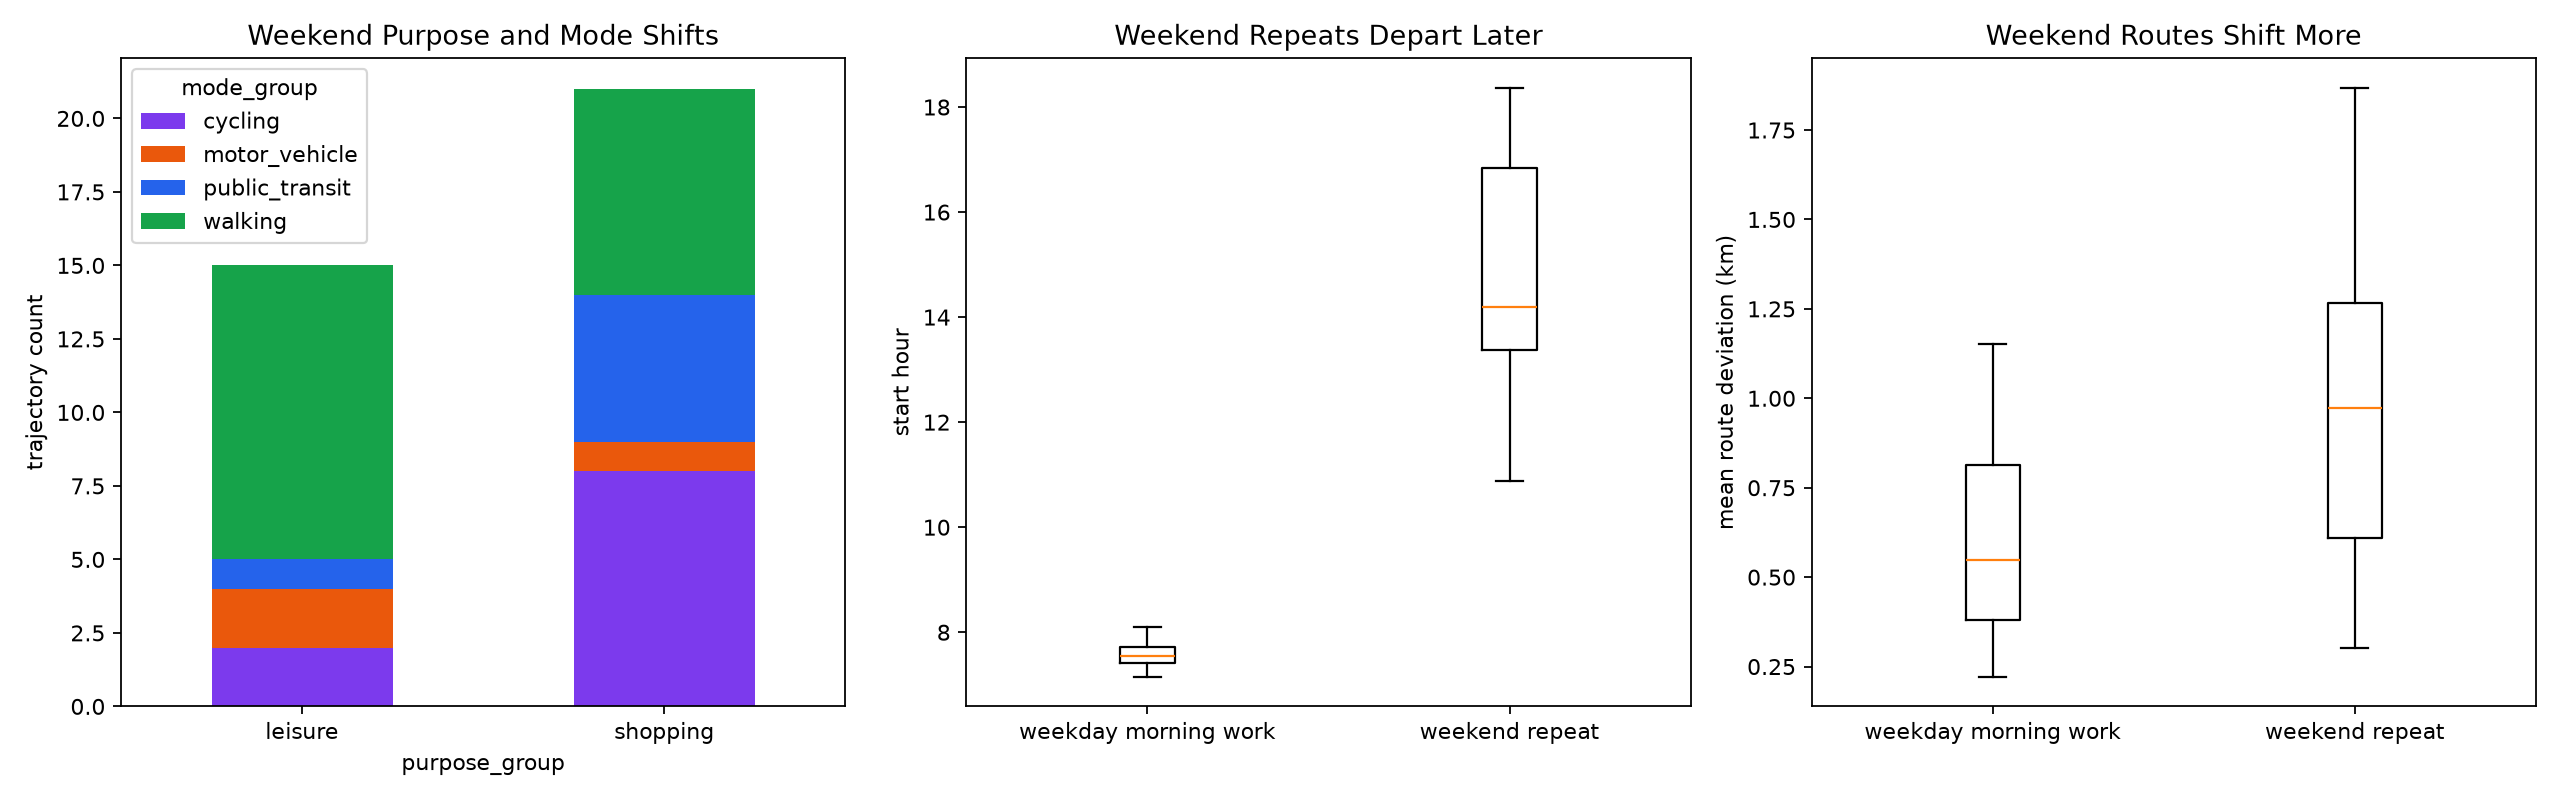

In [ ]:
df.groupby(['day_type','purpose_group','mode_group']).size(); df.groupby('repeat_context').start_hour.agg(['median','std'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/weekend_repeat_shifts.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "weekend_repeat_shift",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Weekend Purpose, Time, Mode, and Route Shifts",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/weekend_repeat_shifts.png"
  },
  "question": "How do weekend repeats differ from weekday work repeats?",
  "code": "df.groupby(['day_type','purpose_group','mode_group']).size(); df.groupby('repeat_context').start_hour.agg(['median','std'])",
  "insight": "Weekend repeats more often shift to shopping or leisure, depart later, and use different modes or routes than weekday repeats.",
  "insight_type": "group_comparison",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "trip_purpose",
    "transport_mode",
    "gps_position"
  ]
}

### Summary of Findings (Flag 20)

Weekday-morning work repeats are the most temporally concentrated, mode-consistent, and direct. Users separate into stable- and variable-route patterns, while weekend repeats shift toward later shopping or leisure travel with different modes and routes.